In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer

In [2]:
def wrangle(filepath):
    df = pd.read_csv(filepath)
    mask_residential = df['propertyType'].isin(['Townhouse', 'Apartment', 'Townhuse'])
    df["Price in Ksh"] = df["Price"].str.replace("KSh", "", regex = False).str.replace("Ksh", "", regex = False).str.replace(",", "", regex = False).str.replace(" ", "", regex = False).astype(float)
    df.drop(columns = df[["House size", "Land size", "Price"]], inplace = True)
    low = df["Price in Ksh"].quantile(0.05)
    high = df["Price in Ksh"].quantile(0.95)
    mask_price = df["Price in Ksh"].between(low, high)
    df = df[mask_residential & mask_price]
    return df

In [3]:
df = wrangle('Nairobi propertyprices - Sheet1.csv')


In [4]:
df.head()

,propertyType,Location,Bedroom,bathroom,Price in Ksh
3,Townhouse,Kitisuru,5.0,5.0,80000000.0
4,Apartment,Kileleshwa,4.0,4.0,25500000.0
5,Townhuse,Runda,6.0,6.0,300000000.0
6,Townhouse,Runda,4.0,4.0,160000000.0
7,Apartment,Kilimani,2.0,2.0,9500000.0


In [5]:
df.count()

propertyType    168
Location        168
Bedroom         168
bathroom        167
Price in Ksh    168
dtype: int64

In [6]:
df.isnull().sum()

propertyType    0
Location        0
Bedroom         0
bathroom        1
Price in Ksh    0
dtype: int64

In [8]:
df.head(3)

,propertyType,Location,Bedroom,bathroom,Price in Ksh
3,Townhouse,Kitisuru,5.0,5.0,80000000.0
4,Apartment,Kileleshwa,4.0,4.0,25500000.0
5,Townhuse,Runda,6.0,6.0,300000000.0


In [9]:
pd.set_option('display.float_format', '{:,.2f}'.format)

In [10]:
imputer = SimpleImputer()
ohe = OneHotEncoder()

In [11]:
features = (df[['propertyType', 'Location', 'Bedroom', 'bathroom']])
target = df['Price in Ksh']
X = features
y = target

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
y_mean = y_train.mean()
y_pred_baseline = [y_mean] * len(y_train)
mae_baseline = mean_absolute_error(y_train, y_pred_baseline)
mae_baseline

60368364.953107595

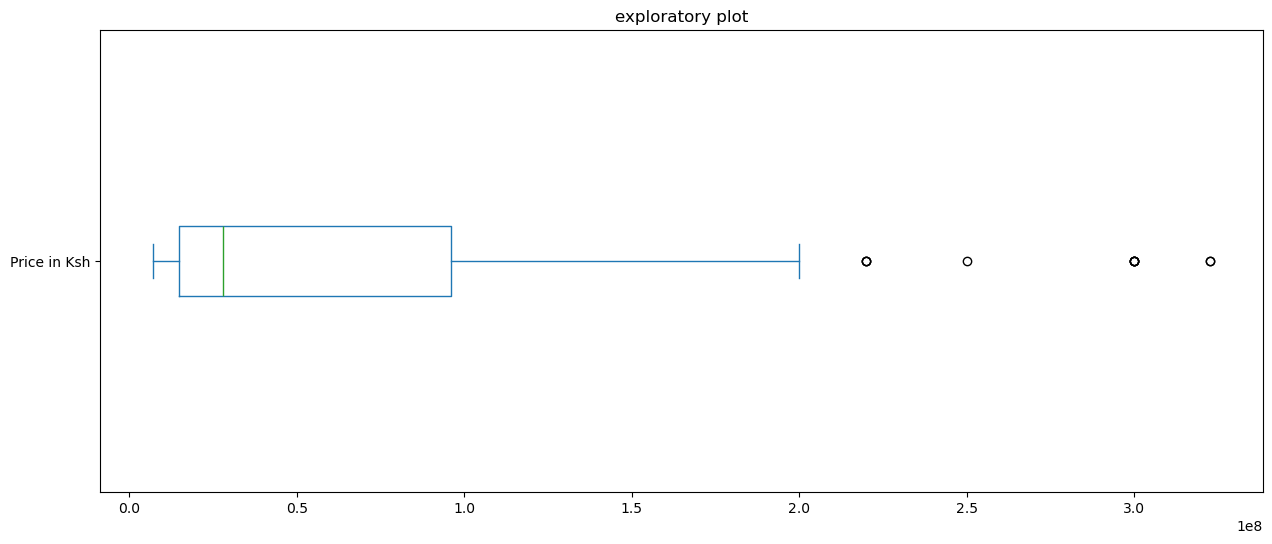

In [14]:
fig, ax = plt.subplots(figsize = (15, 6))
df["Price in Ksh"].plot(kind = "box", vert = False, title = "exploratory plot", ax = ax);

In [15]:
df.describe()

,Bedroom,bathroom,Price in Ksh
count,168.00,167.00,168.00
mean,3.64,2.96,"66,875,508.92"
std,1.53,1.62,"76,705,399.26"
min,1.00,1.00,"7,000,000.00"
25%,2.00,2.00,"14,875,000.00"
50%,4.00,2.00,"28,000,000.00"
75%,5.00,4.00,"96,000,000.00"
max,8.00,8.00,"322,550,000.00"


In [16]:
num_cols = ['Bedroom', 'bathroom']
cat_cols = ['propertyType', 'Location']

preprocessor = ColumnTransformer(
    transformers = [
        ('num', SimpleImputer(strategy = 'median'), num_cols),
        ('cat', OneHotEncoder(handle_unknown = 'ignore'), cat_cols)
    ]
)

In [17]:
model = make_pipeline(preprocessor, LinearRegression())
model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['Bedroom', 'bathroom']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['propertyType',
                                                   'Location'])])),
                ('linearregression', LinearRegression())])

In [18]:
y_pred_training = model.predict(X_train)
mae_training = mean_absolute_error(y_train, y_pred_training)
mae_training

17524403.299797934

In [19]:
y_pred_test = model.predict(X_test)
mae_test = mean_absolute_error(y_test, y_pred_test)
mae_test

21719375.87356291

In [20]:
model.score(X_test, y_test)

0.5480020470272663